In [ ]:
import os
import json
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models
from sklearn.metrics import classification_report


# CONFIGURATION
DATASET_DIR = "Dataset"
MODEL_DIR = "model"

IMG_SIZE = (180, 180)
BATCH_SIZE = 32
EPOCHS = 5
SEED = 42

os.makedirs(MODEL_DIR, exist_ok=True)

In [ ]:
# LOADING DATASET
train_data = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR, validation_split=0.2, subset="training", seed=SEED,
    image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode="int"
)

val_data = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR, validation_split=0.2, subset="validation",seed=SEED, 
    image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode="int")

class_names = train_data.class_names
num_classes = len(class_names)

print("\nNumber of classes:", num_classes)
print("Class names:")
for i, name in enumerate(class_names):
    print(i, name)

# Save class names in the same order used by the model
with open(os.path.join(MODEL_DIR, "class_names.json"), "w") as f:
    json.dump(class_names, f, indent=4)

# Improve input pipeline performance
AUTOTUNE = tf.data.AUTOTUNE
train_data = train_data.prefetch(AUTOTUNE)
val_data = val_data.prefetch(AUTOTUNE)

Found 31574 files belonging to 20 classes.
Using 25260 files for training.
Found 31574 files belonging to 20 classes.
Using 6314 files for validation.

Number of classes: 20
Class names:
0 Apple___Apple_scab
1 Apple___Black_rot
2 Apple___Cedar_apple_rust
3 Apple___healthy
4 Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
5 Corn_(maize)___Common_rust_
6 Corn_(maize)___Northern_Leaf_Blight
7 Corn_(maize)___healthy
8 Potato___Early_blight
9 Potato___Late_blight
10 Potato___healthy
11 Tomato_Bacterial_spot
12 Tomato_Early_blight
13 Tomato_Late_blight
14 Tomato_Leaf_Mold
15 Tomato_Septoria_leaf_spot
16 Tomato__Target_Spot
17 Tomato__Tomato_YellowLeaf__Curl_Virus
18 Tomato__Tomato_mosaic_virus
19 Tomato_healthy


In [ ]:
# DATA AUGMENTATION
augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1)
], name="data_augmentation")

In [ ]:
# BUILDING of CNN MODEL
model = models.Sequential([
    layers.Input(shape=(180, 180, 3)), augmentation, layers.Rescaling(1.0 / 255),

    # Convolution block 1
    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(), layers.MaxPooling2D(),

    # Convolution block 2
    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(), layers.MaxPooling2D(),

    # Convolution block 3
    layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(), layers.MaxPooling2D(),

    # Convolution block 4
    layers.Conv2D(256, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(), layers.MaxPooling2D(),

    # Classification layers
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 180, 180, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 180, 180, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 90, 90, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 90, 90, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 90, 90, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 45, 45, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 45, 45, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 45, 45, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 22, 22, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 22, 22, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 22, 22, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 11, 11, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 20)             │         2,580 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 425,812 (1.62 MB)

 Trainable params: 424,852 (1.62 MB)

 Non-trainable params: 960 (3.75 KB)

In [ ]:
#  CALLBACKS
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=os.path.join(MODEL_DIR, "Plant_disease_model.keras"),
        monitor="val_accuracy", save_best_only=True, mode="max", verbose=1 ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True, verbose=1 ),
        
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1)
]

In [ ]:
#  TRAINING THE MODEL

history = model.fit( train_data, validation_data=val_data, epochs=EPOCHS, callbacks=callbacks )

# Save the final model too
model.save(os.path.join(MODEL_DIR, "plant_disease.keras"))

print("\nTraining completed!")
print("Final model saved in:", MODEL_DIR)

Epoch 1/5
790/790 ━━━━━━━━━━━━━━━━━━━━ 0s 812ms/step - accuracy: 0.5863 - loss: 1.3299
Epoch 1: val_accuracy improved from None to 0.25356, saving model to C:\Users\SPTINT-11\Downloads\archive\model\best_plant_disease.keras
790/790 ━━━━━━━━━━━━━━━━━━━━ 672s 846ms/step - accuracy: 0.6856 - loss: 0.9828 - val_accuracy: 0.2536 - val_loss: 6.8219 - learning_rate: 0.0010
Epoch 2/5
790/790 ━━━━━━━━━━━━━━━━━━━━ 0s 830ms/step - accuracy: 0.8241 - loss: 0.5327
Epoch 2: val_accuracy improved from 0.25356 to 0.81913, saving model to C:\Users\SPTINT-11\Downloads\archive\model\best_plant_disease.keras
790/790 ━━━━━━━━━━━━━━━━━━━━ 683s 864ms/step - accuracy: 0.8403 - loss: 0.4855 - val_accuracy: 0.8191 - val_loss: 0.6903 - learning_rate: 0.0010
Epoch 3/5
790/790 ━━━━━━━━━━━━━━━━━━━━ 0s 824ms/step - accuracy: 0.8907 - loss: 0.3332
Epoch 3: val_accuracy did not improve from 0.81913
790/790 ━━━━━━━━━━━━━━━━━━━━ 677s 857ms/step - accuracy: 0.8962 - loss: 0.3133 - val_accuracy: 0.7867 - val_loss: 0.8227 

In [ ]:
#  EVALUATING THE BEST MODEL

best_model = tf.keras.models.load_model( os.path.join(MODEL_DIR, "Plant_disease_model.keras"))

val_loss, val_accuracy = best_model.evaluate(val_data, verbose=1)

print(f"\nValidation loss: {val_loss:.4f}")
print(f"Validation accuracy: {val_accuracy * 100:.2f}%")

# Classification report
y_true = np.concatenate([ labels.numpy() for _, labels in val_data ])

y_prob = best_model.predict(val_data, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print("\nClassification Report:")
print(classification_report( y_true, y_pred, labels=range(num_classes),
    target_names=class_names, zero_division=0  ))

198/198 ━━━━━━━━━━━━━━━━━━━━ 28s 140ms/step - accuracy: 0.8191 - loss: 0.6903

Validation loss: 0.6903
Validation accuracy: 81.91%
198/198 ━━━━━━━━━━━━━━━━━━━━ 27s 134ms/step

Classification Report:
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.07      0.07      0.07       402
                                 Apple___Black_rot       0.04      0.04      0.04       376
                          Apple___Cedar_apple_rust       0.06      0.05      0.05       364
                                   Apple___healthy       0.07      0.09      0.08       378
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.04      0.04      0.04       293
                       Corn_(maize)___Common_rust_       0.06      0.06      0.06       378
               Corn_(maize)___Northern_Leaf_Blight       0.04      0.04      0.04       390
                            Corn_(maize)___healthy       0.05   

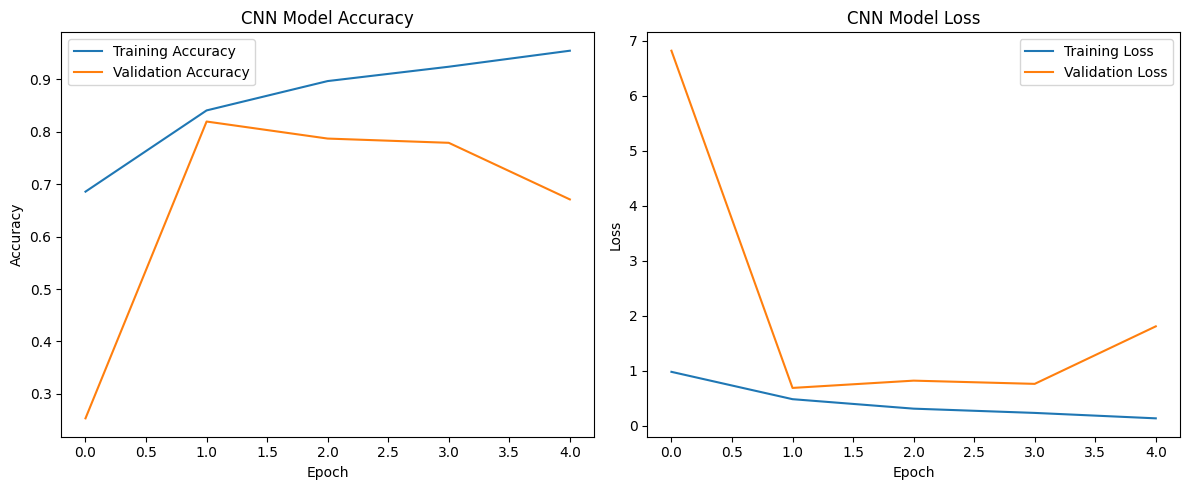

In [ ]:
#  PLOTING ACCURACY AND LOSS

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("CNN Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.savefig("training_results.png", dpi=150)
plt.show()